# Intuition for Matrices using transformations

Applying a matrix to a set of points is easy to draw.

We apply a matrix twice: to a lattice of points, and to a image.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

from pathlib import Path

## Load an image

Any photograph will do. If the file is missing a simple shape is drawn instead.

(1431, 960, 3)


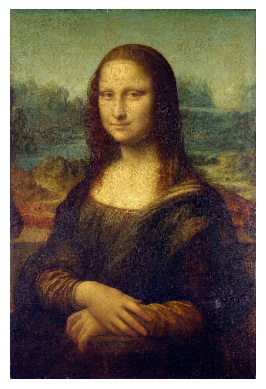

In [8]:
from pathlib import Path
import urllib.request

Path("./data").mkdir(parents=True, exist_ok=True)
IMG = Path("./data/mona_lisa.jpg")
URL = "https://upload.wikimedia.org/wikipedia/commons/thumb/e/ec/Mona_Lisa%2C_by_Leonardo_da_Vinci%2C_from_C2RMF_retouched.jpg/960px-Mona_Lisa%2C_by_Leonardo_da_Vinci%2C_from_C2RMF_retouched.jpg"

req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req, timeout=15) as resp, open(IMG, "wb") as f:
    f.write(resp.read())

if IMG.exists():
    img = cv2.imread(str(IMG))
else:
    img = np.full((480, 320, 3), 235, np.uint8)
    cv2.rectangle(img, (60, 60), (260, 420), (90, 60, 160), -1)
    cv2.circle(img, (160, 160), 60, (200, 180, 120), -1)

print(img.shape)
img = cv2.resize(img, (320, 480))

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Visualise a matrix

[[1.  0.6]
 [0.  1. ]]
column 1: [1. 0.]   column 2: [0.6 1. ]


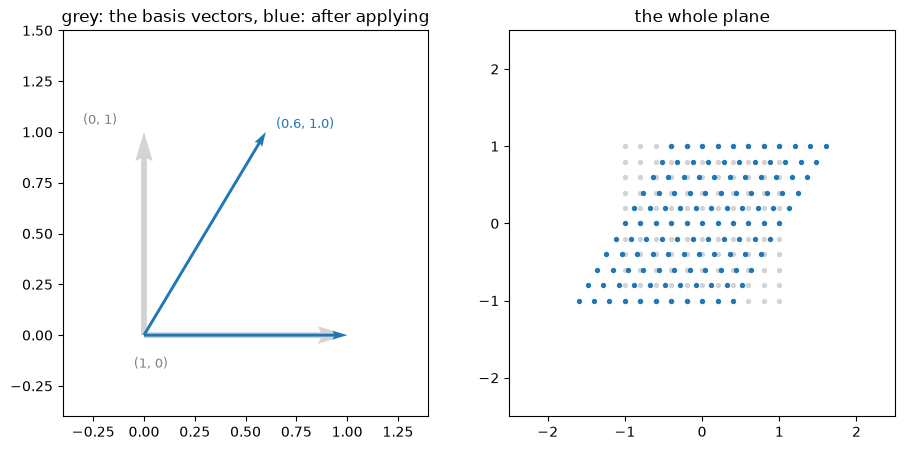

In [10]:
xs = np.linspace(-1, 1, 11)
gx, gy = np.meshgrid(xs, xs)
LATTICE = np.stack([gx.ravel(), gy.ravel()])

A = np.array([[1.0, 0.6], [0.0, 1.0]])

print(A)
print("column 1:", A[:, 0], "  column 2:", A[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6))

for v, c in (((1.0, 0.0), A[:, 0]), ((0.0, 1.0), A[:, 1])):
    axes[0].quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, width=0.016,
                   color="lightgrey", zorder=1)
    axes[0].quiver(0, 0, *c, angles="xy", scale_units="xy", scale=1, width=0.008,
                   color="C0", zorder=2)

axes[0].text(-0.05, -0.16, "(1, 0)", fontsize=9, color="grey")
axes[0].text(0.65, 1.02, "(0.6, 1.0)", fontsize=9, color="C0")
axes[0].text(-0.30, 1.04, "(0, 1)", fontsize=9, color="grey")

axes[0].set_xlim(-0.4, 1.4)
axes[0].set_ylim(-0.4, 1.5)
axes[0].set_aspect("equal")
axes[0].set_title("grey: the basis vectors, blue: after applying")

Q = A @ LATTICE
axes[1].scatter(LATTICE[0], LATTICE[1], s=8, color="lightgrey")
axes[1].scatter(Q[0], Q[1], s=8, color="C0")
axes[1].set_xlim(-2.5, 2.5)
axes[1].set_ylim(-2.5, 2.5)
axes[1].set_aspect("equal")
axes[1].set_title("the whole plane")

plt.tight_layout()
plt.show()

## And same transformation on the image

`cv2.warpAffine` needs a 3x3 matrix (a 2x2 linear map plus a translation), so the
transformation has to be moved to the centre of the image first, otherwise it is applied
about the top-left corner and the picture leaves the frame.

In [11]:
FLIP = np.diag([1.0, -1.0])


def warp(image, A):
    h, w = image.shape[:2]
    linear = FLIP @ np.asarray(A, dtype=float) @ FLIP

    M = np.eye(3)
    M[:2, :2] = linear

    to_centre = np.eye(3)
    to_centre[0, 2] = -w / 2
    to_centre[1, 2] = -h / 2

    back = np.eye(3)
    back[0, 2] = w / 2
    back[1, 2] = h / 2

    M = back @ M @ to_centre
    return cv2.warpAffine(image, M[:2], (w, h))


def show(A, title):
    A = np.asarray(A, dtype=float)
    Q = A @ LATTICE
    ev = np.linalg.eigvals(A)

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))

    axes[0].scatter(LATTICE[0], LATTICE[1], s=7, color="lightgrey")
    axes[0].scatter(Q[0], Q[1], s=7, color="C0")
    axes[0].set_xlim(-2.6, 2.6)
    axes[0].set_ylim(-2.6, 2.6)
    axes[0].set_aspect("equal")
    axes[0].set_title("points")

    axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[1].axis("off")
    axes[1].set_title("before")

    axes[2].imshow(cv2.cvtColor(warp(img, A), cv2.COLOR_BGR2RGB))
    axes[2].axis("off")
    axes[2].set_title("after")

    fig.suptitle(f"{title}   det = {np.linalg.det(A):+.2f}   eigenvalues = "
                 f"{np.round(ev, 2).tolist()}", fontsize=12)
    plt.tight_layout()
    plt.show()

## Identity

The matrix version of multiplying by one. Nothing moves, det = 1, both eigenvalues are 1.

[[1. 0.]
 [0. 1.]]


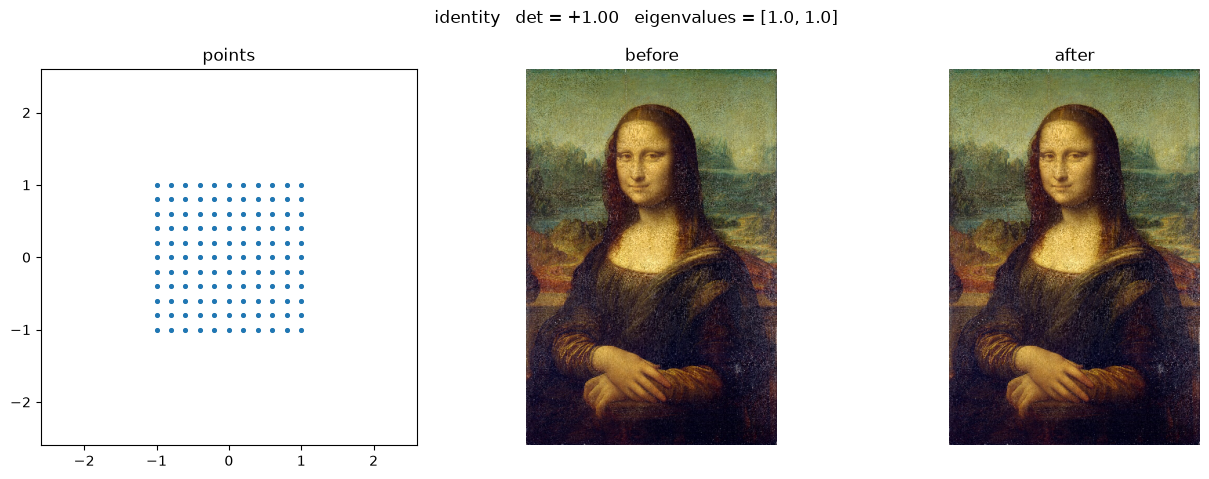

In [12]:
print (np.eye(2))
show(np.eye(2), "identity")

## Scalar matrix

`c * I` scales everything by the same factor in every direction. Area scales by `c^2`, hence
det = 4 for `c = 2`.

[[2. 0.]
 [0. 2.]]


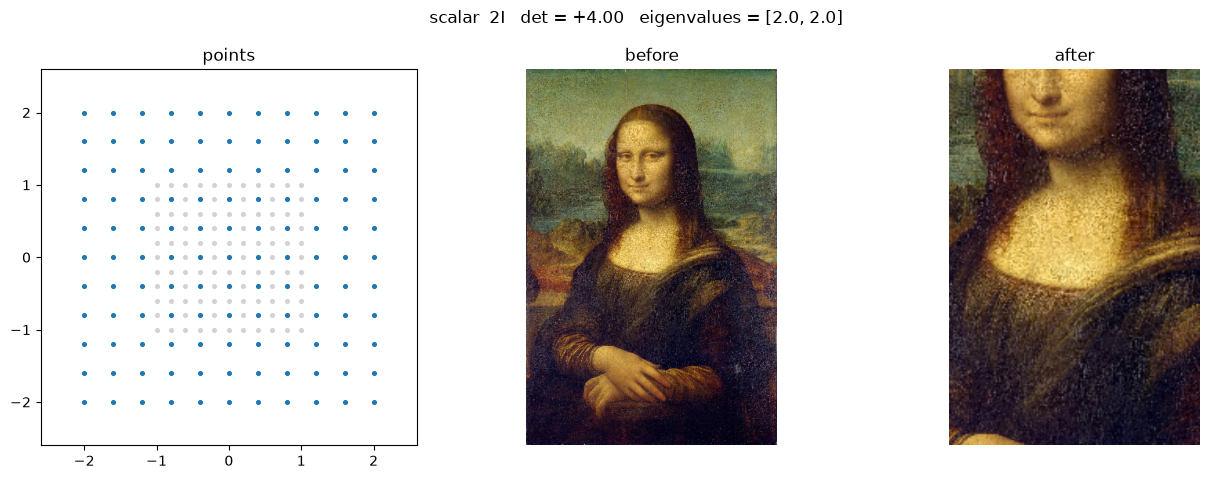

In [13]:
print (2 * np.eye(2))
show(2 * np.eye(2), "scalar  2I")

## A matrix in 3D
Can still be be visualized

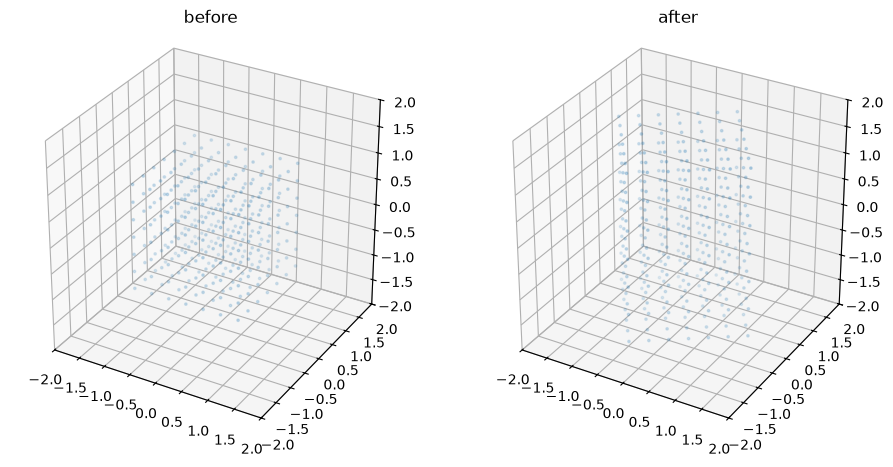

In [18]:
theta = np.deg2rad(35)

A3 = np.array([[np.cos(theta), -np.sin(theta), 0.0],
               [np.sin(theta),  np.cos(theta), 0.0],
               [0.0,            0.0,           1.6]])

g = np.linspace(-1, 1, 7)
X3, Y3, Z3 = np.meshgrid(g, g, g)
P3 = np.stack([X3.ravel(), Y3.ravel(), Z3.ravel()])
Q3 = A3 @ P3

fig = plt.figure(figsize=(9.5, 4.6))

for k, (pts, name) in enumerate(((P3, "before"), (Q3, "after"))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(pts[0], pts[1], pts[2], s=3, alpha=0.5)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_zlim(-2, 2)
    ax.set_title(name)
    ax.set_box_aspect((1, 1, 1))

plt.tight_layout()
plt.show()

## Off-diagonal matrix

[[1.  0.6]
 [0.  1. ]]


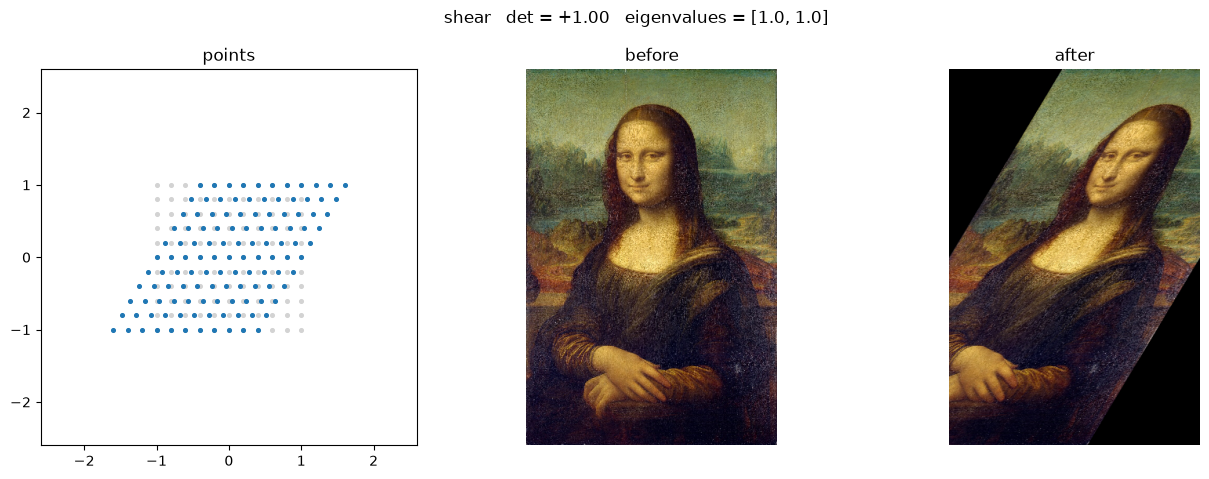

In [22]:
offdiag = np.array([[1.0, 0.6], [0.0, 1.0]]);
print (offdiag)
show(offdiag, "shear")

## Reflection

`[[0, 1], [1, 0]]` swaps the two coordinates, which is a reflection across the diagonal.
det = -1: the area is preserved but the orientation is flipped. A negative determinant
always means the matrix mirrors.

[[0. 1.]
 [1. 0.]]


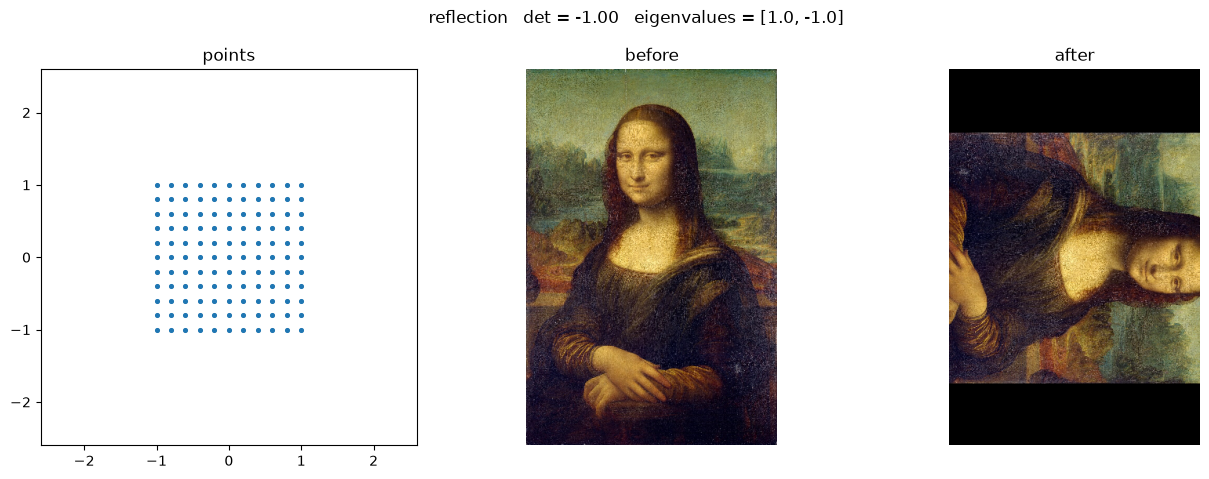

In [23]:
reflectionM = np.array([[0.0, 1.0], [1.0, 0.0]]);
print (reflectionM)
show(reflectionM, "reflection")

## Diagonal matrix

Different factors per axis

[[1.25 0.  ]
 [0.   2.  ]]


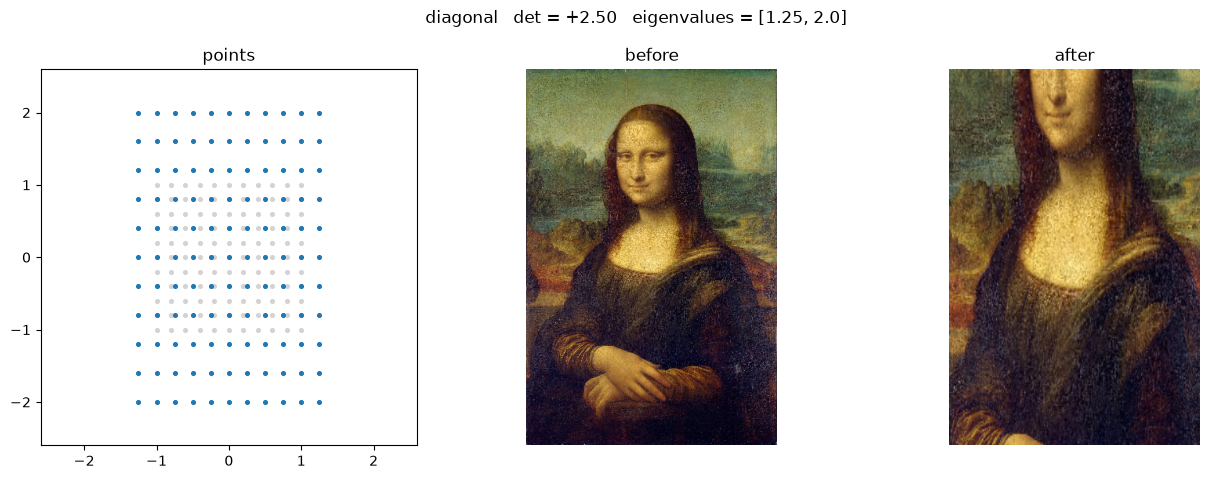

In [30]:
diagonM = np.array([[1.25, 0.0], [0.0, 2.0]]);
print (diagonM)
show(diagonM, "diagonal")

## Zero matrix

Everything collapses to a single point. det = 0, both eigenvalues are 0, and the information
is gone.

[[0. 0.]
 [0. 0.]]


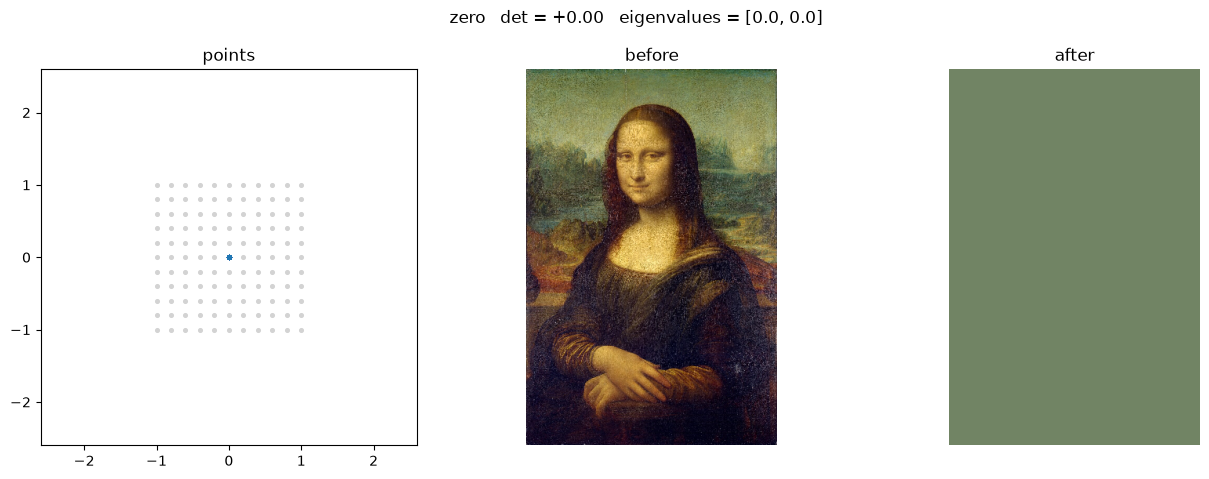

In [31]:
print (np.zeros((2, 2)))
show(np.zeros((2, 2)), "zero")

## Why is this important for PCA

The covariance matrix of a data cloud is a matrix like the ones above. Its **eigenvectors**
are the directions of the ellipse and its **eigenvalues** say how far the cloud extends along
them.

PCA is the rotation that turns the cloud until those directions line up with the axes; a
change of basis.

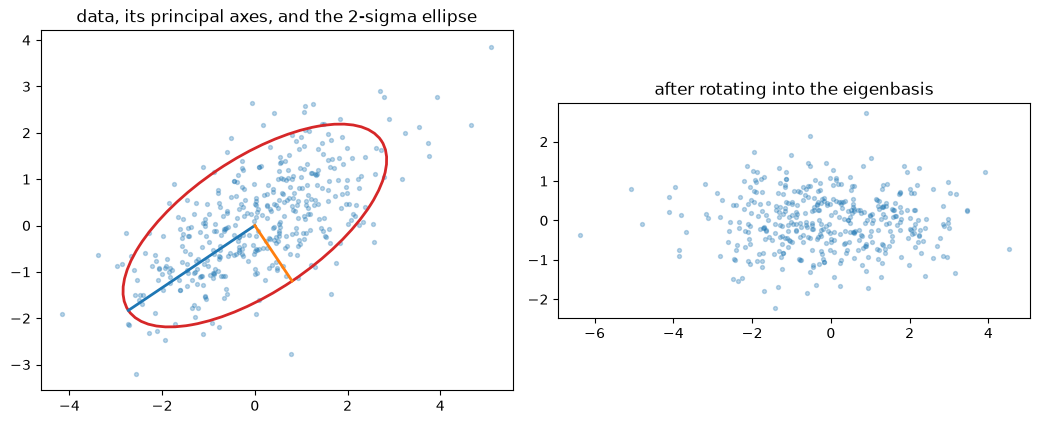

eigenvalues: [2.698 0.52 ]
variance kept by the first axis: 83.8%


In [13]:
from matplotlib.patches import Ellipse

rng = np.random.default_rng(0)
X = rng.multivariate_normal([0, 0], [[2.0, 1.0], [1.0, 1.2]], 400)

C = np.cov(X.T)
values, vectors = np.linalg.eigh(C)
order = np.argsort(values)[::-1]
values, vectors = values[order], vectors[:, order]
angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8))

axes[0].scatter(X[:, 0], X[:, 1], s=8, alpha=0.3)
axes[0].add_patch(Ellipse((0, 0), 4 * np.sqrt(values[0]), 4 * np.sqrt(values[1]),
                          angle=angle, fill=False, lw=2, color="C3"))
for i in range(2):
    d = vectors[:, i] * 2 * np.sqrt(values[i])
    axes[0].plot([0, d[0]], [0, d[1]], lw=2)
axes[0].set_title("data, its principal axes, and the 2-sigma ellipse")
axes[0].set_aspect("equal")

Y = X @ vectors
axes[1].scatter(Y[:, 0], Y[:, 1], s=8, alpha=0.3)
axes[1].set_title("after rotating into the eigenbasis")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

print("eigenvalues:", np.round(values, 3))
print("variance kept by the first axis:", f"{values[0] / values.sum():.1%}")